# Modul Simulasi: Perancangan Root Locus Robot *Line Follower* 

Studi Kasus: mencari nilai *Gain* ($K$) yang tepat agar kemudi robot *line follower* kita tidak mengalami *overshoot* lebih dari **10%** (Rasio redaman $\zeta \approx 0.59$). Kita akan menggunakan fungsi alih plant fisis motor kemudi: $G(s) = \frac{1}{s(s+2)(s+4)}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
import warnings

ignore_warnings = True
warnings.filterwarnings("ignore") if ignore_warnings else None

plt.style.use('seaborn-v0_8-darkgrid')

### 1. Mendefinisikan *Plant* Fisis (Motor Kemudi Robot)
Fungsi alih $G(s)$ memiliki 3 *Pole* di $s=0, -2, -4$. Kita masukkan koefisien penyebutnya: $(s)(s+2)(s+4) = s^3 + 6s^2 + 8s$.

In [2]:
# Pembilang (Numerator) dan Penyebut (Denominator)
num = [1]
den = [1, 6, 8, 0] # merepresentasikan 1s^3 + 6s^2 + 8s + 0

# Membuat objek Transfer Function
G = ct.TransferFunction(num, den)
print("Fungsi Alih Plant Kemudi Robot:\n", G)

Fungsi Alih Plant Kemudi Robot:
 <TransferFunction>: sys[0]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

          1
  -----------------
  s^3 + 6 s^2 + 8 s


### 2. Menggambar Peta Jejak Kaki (Root Locus)
Garis-garis lengkung putus-putus pada grafik (grid) merepresentasikan nilai rasio redaman ($\zeta$) konstan.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


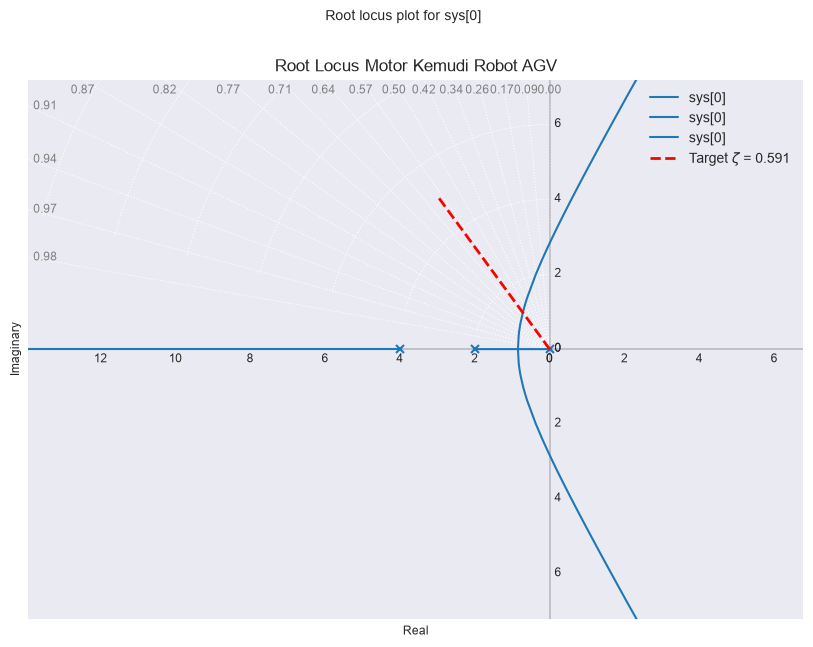

In [3]:
# Menggambar Root Locus
plt.figure(figsize=(10, 7))
roots, gains = ct.root_locus(G, plot=True, grid=True)

# Menambahkan garis target redaman zeta = 0.59 (Overshoot 10%)
zeta_target = 0.591
theta = np.arccos(zeta_target)
# Membuat garis radial untuk panduan visual target kita
r = np.linspace(0, 5, 100)
x_line = -r * np.cos(theta)
y_line = r * np.sin(theta)
plt.plot(x_line, y_line, 'r--', linewidth=2, label=f'Target $\zeta$ = {zeta_target}')

plt.title('Root Locus Motor Kemudi Robot AGV')
plt.legend()
plt.show()

### 3. Eksekusi Desain: Menemukan Nilai Gain ($K$) yang Pas
Grafik di atas menunjukkan bahwa kurva biru (Root Locus) memotong garis merah putus-putus (Target Redaman). Tugas berikutnya adalah mencari berapa tepatnya nilai *Gain* ($K$) di titik tabrakan tersebut.

In [4]:
# Menyapu (looping) semua kombinasi gain dan akar untuk mencari zeta yang cocok
K_terpilih = 0
titik_sd = 0
zeta_terdekat = 1.0 # Inisialisasi awal

for i in range(len(gains)):
    # Ambil akar yang kompleks (karena osilasi selalu dari akar kompleks)
    akar_kompleks = roots[i][1] 
    
    # Lewati jika akarnya masuk zona tidak stabil (sebelah kanan)
    if akar_kompleks.real >= 0:
        continue
        
    # Hitung nilai zeta dari letak koordinat akar: zeta = cos(theta)
    sudut = np.arctan2(abs(akar_kompleks.imag), abs(akar_kompleks.real))
    zeta_sekarang = np.cos(sudut)
    
    # Cari yang selisihnya paling kecil dengan 0.591
    if abs(zeta_sekarang - 0.591) < abs(zeta_terdekat - 0.591):
        zeta_terdekat = zeta_sekarang
        K_terpilih = gains[i]
        titik_sd = akar_kompleks

print(f"Spesifikasi terpenuhi di Titik Target (s_d) = {titik_sd:.2f}")
print(f"Gain (K) yang harus disetel di mikrokontroler robot = {K_terpilih:.2f}")

Spesifikasi terpenuhi di Titik Target (s_d) = -0.71+1.01j
Gain (K) yang harus disetel di mikrokontroler robot = 6.93


### 4. Validasi Hasil Akhir: Uji *Step Response*
Masukkan nilai $K$ sesuai hasil komputasi di atas ke dalam rangkaian *Closed-Loop* robot, lalu kita beri perintah belok mendadak (*Step input*). Ukur apakah *overshoot* tegangannya benar-benar tidak lebih dari 10%.

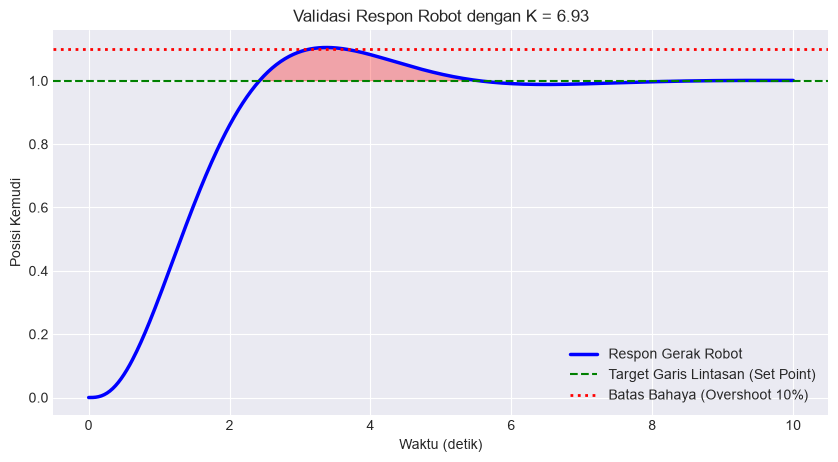

Misi Berhasil! Persentase Overshoot aktual robot: 10.51%


In [7]:
# Membuat fungsi alih Loop Tertutup dengan K yang sudah kita desain
K_ = K_terpilih
Sistem_Tertutup = ct.feedback(K_ * G, 1)

# Mensimulasikan respon waktu selama 10 detik
waktu, respon = ct.step_response(Sistem_Tertutup, T=np.linspace(0, 10, 500))

# Visualisasi
plt.figure(figsize=(10, 5))
plt.plot(waktu, respon, 'b-', linewidth=2.5, label='Respon Gerak Robot')
plt.axhline(y=1.0, color='g', linestyle='--', label='Target Garis Lintasan (Set Point)')
plt.axhline(y=1.1, color='r', linestyle=':', linewidth=2, label='Batas Bahaya (Overshoot 10%)')

plt.title(f'Validasi Respon Robot dengan K = {K_:.2f}')
plt.xlabel('Waktu (detik)')
plt.ylabel('Posisi Kemudi')
plt.legend(loc='lower right')
plt.fill_between(waktu, respon, 1.0, where=(respon > 1.0), color='red', alpha=0.3)
plt.show()

# Menghitung overshoot aktual menggunakan metrik info respon
info = ct.step_info(Sistem_Tertutup)
print(f"Misi Berhasil! Persentase Overshoot aktual robot: {info['Overshoot']:.2f}%")